# 2D Transient Heat Conduction In a Homogeneous Material: Numerical Solution

Consider a 2D rectangular physical domain $[0, L] \times [0, H]$ and continuous time $t \ge 0$. We discretize the domain into a uniform Cartesian grid:

* $\Delta x = \frac{L}{N_x - 1}$ and $\Delta y = \frac{H}{N_y - 1}$, where $N_x$ and $N_y$ are the total number of nodal points in $x$ and $y$.
* $\Delta t > 0$.
    * $x_i = (i-1)\Delta x$ for $i = 1, 2, \dots, N_x$,
    * $y_j = (j-1)\Delta y$ for $j = 1, 2, \dots, N_y$, and
    * $t^n = n \Delta t$ for $n = 0, 1, 2, \dots$
* $T_{i,j}^n \approx T(x_i, y_j, t^n)$.

We will use a finite difference approximation (FTCS scheme). We will use a second-order central difference technique for determining the spatial derivatives. Expanding $T(x_i \pm \Delta x, y_j, t^n)$ in Taylor series around $(x_i, y_j, t^n)$:

$$T(x_i + \Delta x, y_j, t^n) = T_{i,j}^n + \Delta x \left.\frac{\partial T}{\partial x}\right\vert{}_{i,j}^n + \frac{\Delta x^2}{2} \left.\frac{\partial^2 T}{\partial x^2}\right\vert{}_{i,j}^n + \frac{\Delta x^3}{6} \left.\frac{\partial^3 T}{\partial x^3}\right\vert{}_{i,j}^n + \mathcal{O}(\Delta x^4)$$

$$T(x_i - \Delta x, y_j, t^n) = T_{i,j}^n - \Delta x \left.\frac{\partial T}{\partial x}\right\vert{}_{i,j}^n + \frac{\Delta x^2}{2} \left.\frac{\partial^2 T}{\partial x^2}\right\vert{}_{i,j}^n - \frac{\Delta x^3}{6} \left.\frac{\partial^3 T}{\partial x^3}\right\vert{}_{i,j}^n + \mathcal{O}(\Delta x^4)$$

Adding these two equations eliminates odd-order derivative terms and yields:

$$\left.\frac{\partial^2 T}{\partial x^2}\right\vert{}_{i,j}^n = \frac{T_{i+1,j}^n - 2 T_{i,j}^n + T_{i-1,j}^n}{\Delta x^2} + \mathcal{O}(\Delta x^2)$$

By symmetry, the second partial derivative with respect to $y$ is:

$$\left.\frac{\partial^2 T}{\partial y^2}\right\vert{}_{i,j}^n = \frac{T_{i,j+1}^n - 2 T_{i,j}^n + T_{i,j-1}^n}{\Delta y^2} + \mathcal{O}(\Delta y^2)$$

For the temporal derivative, we will use a first-order forward difference technique. Expanding $T(x_i, y_j, t^n + \Delta t)$ forward in time:

$$T(x_i, y_j, t^n + \Delta t) = T_{i,j}^n + \Delta t \left.\frac{\partial T}{\partial t}\right\vert{}_{i,j}^n + \mathcal{O}(\Delta t^2)$$

Solving for the temporal rate of change gives:

$$\left.\frac{\partial T}{\partial t}\right\vert{}_{i,j}^n = \frac{T_{i,j}^{n+1} - T_{i,j}^n}{\Delta t} + \mathcal{O}(\Delta t)$$

Substituting the derivative approximations into the continuous heat equation $\frac{\partial T}{\partial t} = \alpha \left( \frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2} \right)$:

$$\frac{T_{i,j}^{n+1} - T_{i,j}^n}{\Delta t} = \alpha \left( \frac{T_{i+1,j}^n - 2 T_{i,j}^n + T_{i-1,j}^n}{\Delta x^2} + \frac{T_{i,j+1}^n - 2 T_{i,j}^n + T_{i,j-1}^n}{\Delta y^2} \right)$$

Defining mesh Fourier numbers:

$$r_x = \frac{\alpha \Delta t}{\Delta x^2}, \quad r_y = \frac{\alpha \Delta t}{\Delta y^2}$$

Isolating the unknown state $T_{i,j}^{n+1}$ yields the explicit update equation:

$$T_{i,j}^{n+1} = T_{i,j}^n + r_x \left( T_{i+1,j}^n - 2 T_{i,j}^n + T_{i-1,j}^n \right) + r_y \left( T_{i,j+1}^n - 2 T_{i,j}^n + T_{i,j-1}^n \right)$$

For a square spatial grid ($\Delta x = \Delta y = \Delta s \implies r_x = r_y = r$):

$$T_{i,j}^{n+1} = (1 - 4r) T_{i,j}^n + r \left( T_{i+1,j}^n + T_{i-1,j}^n + T_{i,j+1}^n + T_{i,j-1}^n \right)$$

For the explicit FTCS scheme to avoid unbounded numerical oscillations, the discrete growth factor $G \le 1$. In 2D, this imposes a strict restriction on time step size:

$$r_x + r_y \le \frac{1}{2}$$

When $\Delta x = \Delta y = \Delta s$:

$$r = \frac{\alpha \Delta t}{\Delta s^2} \le \frac{1}{4} \implies \Delta t \le \frac{\Delta s^2}{4 \alpha}$$

For our boundary nodes, we will use a Dirichlet condition:

$$T_{1, j}^n = T_0, \quad T_{N_x, j}^n = T_0 \quad (1 \le j \le N_y)$$

$$T_{i, 1}^n = T_0, \quad T_{i, N_y}^n = T_0 \quad (1 \le i \le N_x)$$


For the interior nodes at time zero, we will use:

$$T_{i, j}^0 = T_i \quad (2 \le i \le N_x - 1, \; 2 \le j \le N_y - 1)$$

Grid Size: 50 x 50
Time Step dt: 0.8314 s | Total Time Steps: 204
Mesh Fourier numbers: rx = 0.1996, ry = 0.1996 (Sum = 0.3992 <= 0.5)
Max Absolute Error at t = 169.6s: 0.0898 °C


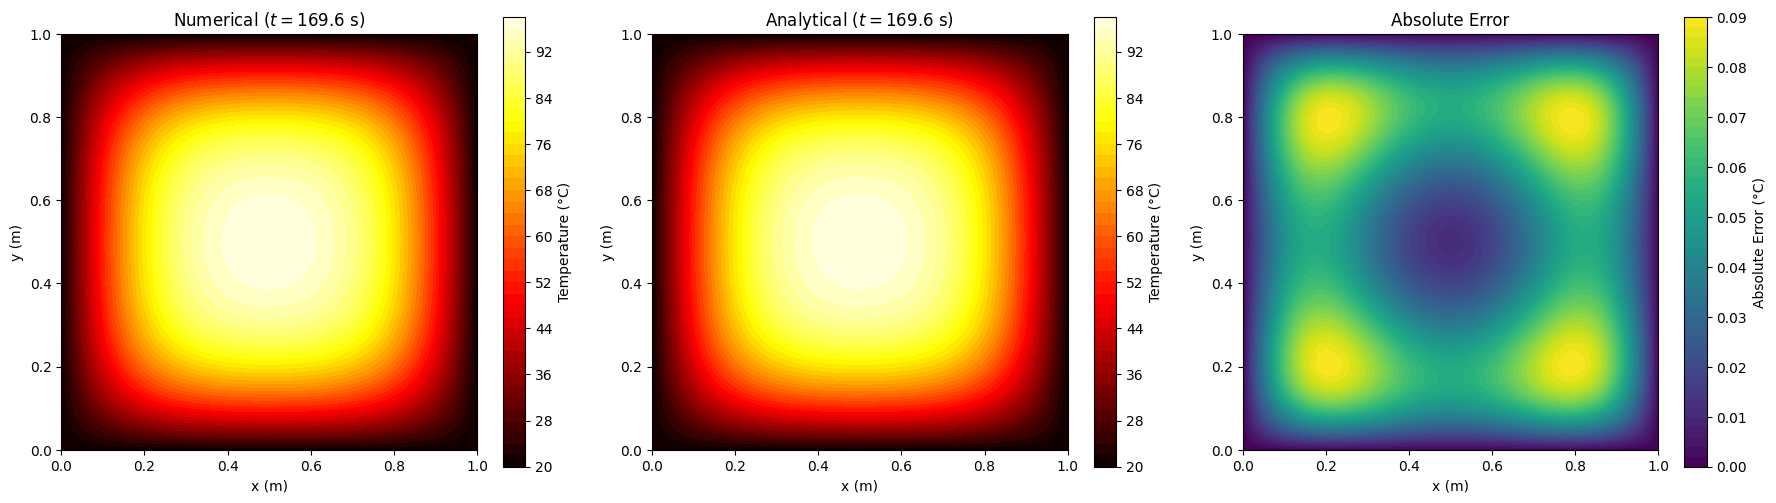

In [6]:
import numpy as np
import matplotlib.pyplot as plt
'''
The code below implements the 2D explicit finite difference method vectorized in NumPy, 
computes the exact analytical double Fourier series solution on the same grid, and plots a 
side-by-side comparison along with the absolute error field.
'''

# ---------------------------------------------
# Inputs
# ---------------------------------------------
L = 1.0          # Domain width in x (m)
H = 1.0          # Domain height in y (m)
alpha = 1e-4     # Thermal diffusivity (m^2/s)
T0 = 20.0        # Homogeneous boundary temperature (°C)
Ti = 100.0       # Initial uniform internal temperature (°C)
# t_eval = 500.0   # Evaluation time (s)
t_eval = 169.6   # Evaluation time (s)
Nx, Ny = 50, 50

# ---------------------------------------------
# Initialization
# ---------------------------------------------
dx = L / (Nx - 1)
dy = H / (Ny - 1)
x = np.linspace(0, L, Nx)
y = np.linspace(0, H, Ny)
X, Y = np.meshgrid(x, y)
# Stability condition: alpha * dt * (1/dx^2 + 1/dy^2) <= 0.5
dt_max = 0.5 / (alpha * (1.0 / dx**2 + 1.0 / dy**2))
safety_factor = 0.8
dt = safety_factor * dt_max
# Adjust dt so we hit t_eval exactly
nt = int(np.ceil(t_eval / dt))
dt = t_eval / nt
rx = alpha * dt / dx**2
ry = alpha * dt / dy**2

print(f"Grid Size: {Nx} x {Ny}")
print(f"Time Step dt: {dt:.4f} s | Total Time Steps: {nt}")
print(f"Mesh Fourier numbers: rx = {rx:.4f}, ry = {ry:.4f} (Sum = {rx + ry:.4f} <= 0.5)")

# ---------------------------------------------
# Calculations
# ---------------------------------------------
T_num = np.full((Ny, Nx), Ti, dtype=np.float64)

# Apply Boundary Conditions
T_num[0, :] = T0
T_num[-1, :] = T0
T_num[:, 0] = T0
T_num[:, -1] = T0

# Time-stepping loop 
for n in range(nt):
    Tn = T_num.copy()
    T_num[1:-1, 1:-1] = (
        Tn[1:-1, 1:-1]
        + rx * (Tn[1:-1, 2:] - 2.0 * Tn[1:-1, 1:-1] + Tn[1:-1, :-2])
        + ry * (Tn[2:, 1:-1] - 2.0 * Tn[1:-1, 1:-1] + Tn[:-2, 1:-1])
    )

# ---------------------------------------------
# Analytical solution
# ---------------------------------------------
def compute_exact_solution(X, Y, t, L, H, alpha, T0, Ti, terms=41):
    T_exact = np.full_like(X, fill_value=float(T0))
    for m in range(1, terms, 2):
        for n in range(1, terms, 2):
            c_mn = (16.0 * (Ti - T0)) / ((np.pi**2) * m * n)
            spatial = np.sin(m * np.pi * X / L) * np.sin(n * np.pi * Y / H)
            decay = np.exp(-alpha * (np.pi**2) * ((m / L)**2 + (n / H)**2) * t)
            T_exact += c_mn * spatial * decay
    return T_exact

T_exact = compute_exact_solution(X, Y, t_eval, L, H, alpha, T0, Ti)
abs_error = np.abs(T_num - T_exact)

print(f"Max Absolute Error at t = {t_eval}s: {np.max(abs_error):.4f} °C")

# ---------------------------------------------
# Plotting
# ---------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

c1 = axes[0].contourf(X, Y, T_num, levels=50, cmap='hot', vmin=T0, vmax=Ti)
fig.colorbar(c1, ax=axes[0], label='Temperature (°C)')
axes[0].set_title(f'Numerical ($t = {t_eval}$ s)', fontsize=12)
axes[0].set_xlabel('x (m)')
axes[0].set_ylabel('y (m)')
axes[0].set_aspect('equal')

c2 = axes[1].contourf(X, Y, T_exact, levels=50, cmap='hot', vmin=T0, vmax=Ti)
fig.colorbar(c2, ax=axes[1], label='Temperature (°C)')
axes[1].set_title(f'Analytical ($t = {t_eval}$ s)', fontsize=12)
axes[1].set_xlabel('x (m)')
axes[1].set_ylabel('y (m)')
axes[1].set_aspect('equal')

c3 = axes[2].contourf(X, Y, abs_error, levels=50, cmap='viridis')
fig.colorbar(c3, ax=axes[2], label='Absolute Error (°C)')
axes[2].set_title('Absolute Error', fontsize=12)
axes[2].set_xlabel('x (m)')
axes[2].set_ylabel('y (m)')
axes[2].set_aspect('equal')

plt.tight_layout()
plt.savefig('../lectures/figures/x_y_T_heat_conduction_numerical.pdf',dpi=300)
plt.show()